# Group the definitions by meaning

Cluster the definitions of **media bias and its subtypes down to two steps** by meaning, and draw how many passages, terms and papers the ten largest clusters cover. The definitions are screened for English, embedded with MiniLM, reduced to 50 principal components, normalised and clustered with HDBSCAN. A TF–IDF clustering of the same passages is the baseline, and other HDBSCAN settings test the sensitivity. No generative LLM and no training is used.

## Load MBDef
`load()` reads MBDef's five tables from `$DATA_ROOT/MBDef/data/`, where `uv run mbdef data fetch MBDef/` puts them after checking each file's sha256. Pass a folder, `load("path/to/data")`, to read another copy of the parquet files. Each table is a [polars](https://docs.pola.rs/) DataFrame.

In [1]:
import json
from pathlib import Path

from mbdef.analysis import load

OUTPUTS = Path("outputs")  # tutorials/outputs/, not tracked by git
data = load()

## Configure and run the clustering
The subtypes come from the `subtypes` and `supertypes` that the papers report, as linked to merged terms in the `terms` table. Definitions shorter than eight words once their citation strings are removed are left out; identical passages are clustered once and keep every source. A passage is kept when seeded `langdetect` gives English a probability of at least 0.8 and every word of one of its terms has an English `wordfreq` Zipf frequency of at least 1. This heuristic can drop rare English terminology; what it drops is written to `language_exclusions.json`. Terms are not translated.

The encoder is `sentence-transformers/all-MiniLM-L6-v2` at revision `1110a243fdf4706b3f48f1d95db1a4f5529b4d41`. The vectors are normalised, reduced by PCA to at most 50 dimensions and normalised again; HDBSCAN uses Euclidean distance, leaf selection, a minimum cluster size of 20 and 5 minimum samples. The model downloads on first use; on a CPU the run takes a few minutes. The embeddings are cached in the output folder and reused while the model and the passages stay the same.

In [2]:
from mbdef.analysis.clustering import make_figure, run

cluster_output = OUTPUTS / "definition-cluster"
run(
    data,
    cluster_output,
    root="media bias",
    depth=2,
    min_words=8,
    min_cluster_size=20,
    min_samples=5,
)
make_figure(cluster_output)

Selected 5,547 unique passages from 282 candidate terms.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/87 [00:00<?, ?it/s]

Clustering finished; running sensitivity checks.


Saved clustering data to outputs/definition-cluster


Saved outputs/definition-cluster/definition-cluster.svg (5,547 passages; 27 clusters).


{
  "clusters": 27,
  "assigned_fraction": 0.29385253290066704,
  "unassigned": 3917,
  "silhouette_assigned": 0.32393357157707214
}
Selected passages: 5547


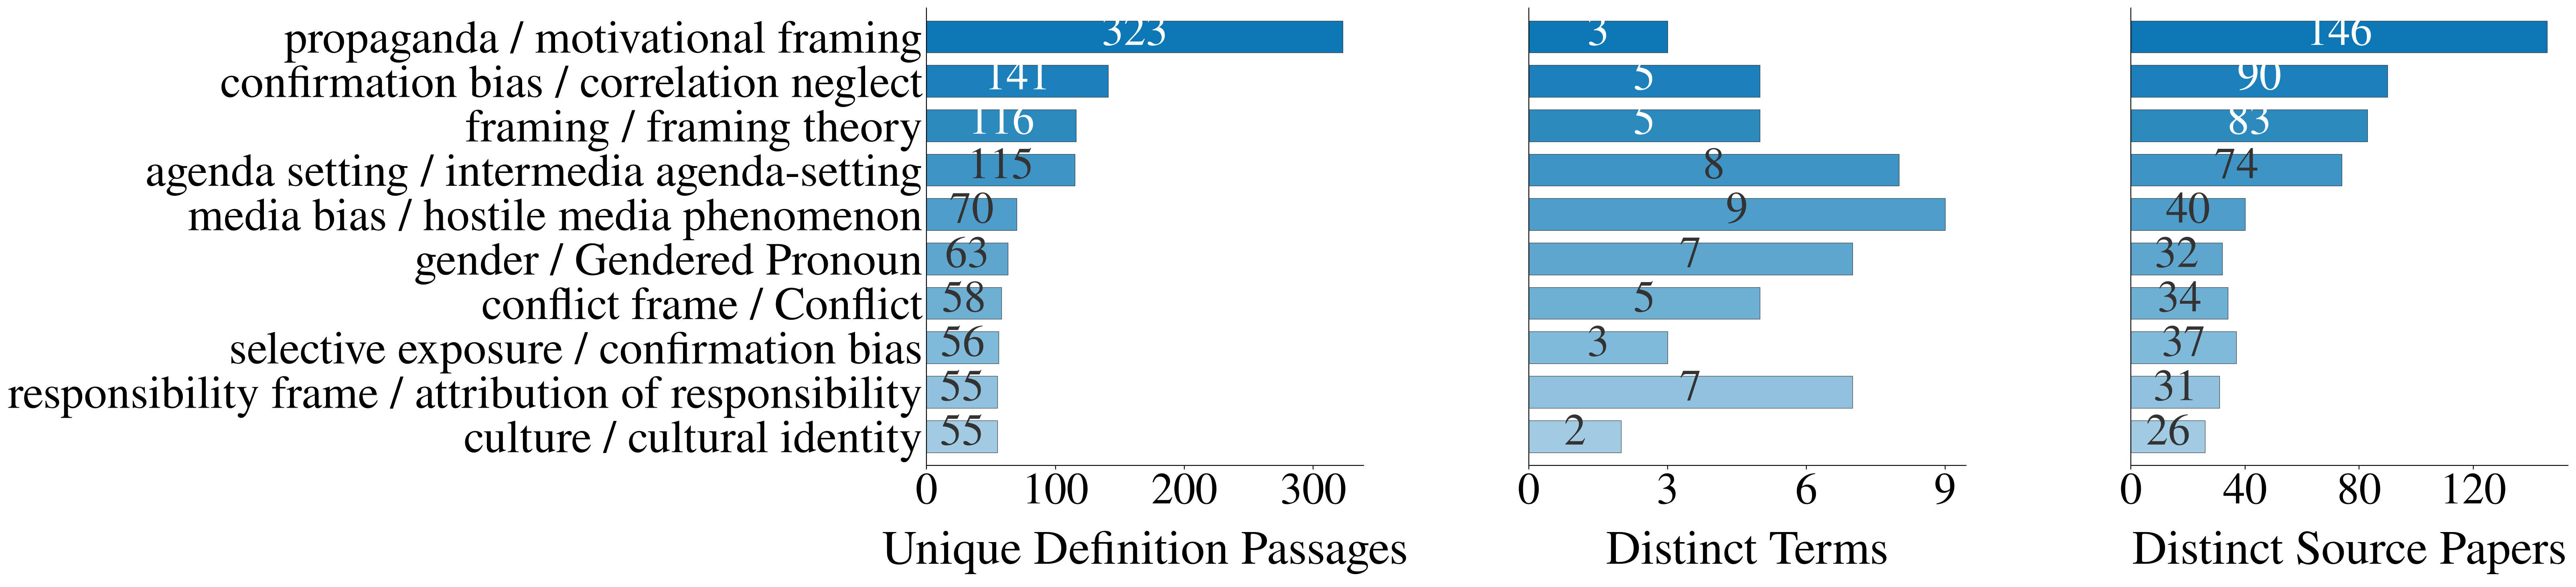

In [3]:
from IPython.display import Image, display

report = json.loads((cluster_output / "cluster_report.json").read_text())
print(json.dumps(report["semantic_metrics"], indent=2))
print("Selected passages:", report["selection"]["unique_passages"])
display(Image(filename=str(cluster_output / "definition-cluster.png")))

## Read the meanings behind the bars
Each bar is named by the two terms that the most of its passages define. A term or a paper can occur in several clusters, so the term and paper counts do not add up to totals. The names summarise; they are not validated taxonomy categories.

In [4]:
for cluster in report["clusters"][:3]:
    print("\nTerms:", cluster["top_terms"][:2])
    print("Passages:", cluster["passages"], "Papers:", cluster["distinct_papers"])
    for example in cluster["representatives"][:2]:
        print("-", example["text"])
print("Sensitivity settings:", len(report["sensitivity"]))


Terms: [['propaganda', 322], ['persuasion', 1]]
Passages: 323 Papers: 146
- Propaganda is a form of communication intended to influence the opinions and the mindset of the public to promote a particular agenda.
- propaganda as a systematic information activity aimed at manipulating the thoughts, beliefs, and emotions of the public in order to form certain ideas, beliefs, or support specific political, ideological, or social goals

Terms: [['confirmation bias', 132], ['selective exposure', 3]]
Passages: 141 Papers: 90
- confirmation bias, which occurs when individuals are biased to seek information that relates to what they already believe
- confirmation bias, i.e. the tendency to find and interpret information exclusively in a way that supports their existing beliefs.

Terms: [['framing', 113], ['framing theory', 2]]
Passages: 116 Papers: 83
- Framing is to 'select some aspects of a perceived reality and make them more salient in a communicating text, in such a way as to promote a par

### Interpretation
Clusters suggest recurring themes and candidate entries for expert review. A passage left unassigned may belong to a sparse topic or be worded unusually; it is neither an error nor irrelevant. On MBDef 1.0.0 the run found 27 clusters, which hold 1,630 of the 5,547 passages (29.4%); the rest stayed unassigned. Library and hardware versions can move passages near a cluster's boundary. Read `cluster_report.json`, `cluster_assignments.csv`, `language_exclusions.json` and the representative passages alongside the figure.